CD704: Exercises, Week 7

17 November 2026

You may need LLM / AI help for the following exercises.


# Exercise 1 (Kernel Ridge Regression). 

Load the $\mathtt{scikit-learn}$ California Housing dataset and select a random subset of size 2000. 
Split this subset into training (80%) and test (20%) sets.

1. Fit a $\mathtt{KernelRidge}$ model with an RBF kernel and default hyperparameters directly
on the unscaled training data, and record the test MSE and $R^2$. Next, build a
pipeline combining $\mathtt{StandardScaler}$ and $\mathtt{KernelRidge}$, evaluate it on the same
split, and compare the results.

2. Using pipelines with $\mathtt{StandardScaler}$, try $\mathtt{KernelRidge}$ with four kernels: $\mathtt{linear}$,
$\mathtt{poly}$, $\mathtt{rbf}$, and $\mathtt{laplacian}$. Use $\mathtt{GridSearchCV}$ or $\mathtt{RandomizedSearchCV}$ to tune the
regularisation parameter alpha along with the kernel parameters ($\mathtt{gamma}$, $\mathtt{degree}$,
$\mathtt{coef0}$. Compare the best test $R^2$ across the four kernels. How does the linear
kernel compare to standard ridge regression?

3. Fix a test set of 1000 instances from the full California Housing dataset. Using your
best tuned RBF pipeline, measure both the fitting time ($\mathtt{.fit()}$) and the prediction
time ($\mathtt{.predict()}$) for training set sizes $N$ growing from 200 to 8000 (for example,
200, 500, 1000, 2000, 4000, 8000). Plot both running times against $N$ (you may need
log–log axes). Do your empirical timings relate to the $O(n^3)$ training complexity in
the lecture?

## Response

### Download and Split the Dataset

In [14]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_squared_error
from sklearn.metrics.pairwise import PAIRWISE_KERNEL_FUNCTIONS, pairwise_kernels
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from timeit import default_timer as timer
import warnings

# Load the california housing dataset and split it into training and test sets.

california = fetch_california_housing(data_home="../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

df = pd.DataFrame(X, columns=california.feature_names)
df = pd.concat([df, pd.DataFrame(y, columns=['target'])], axis=1)

# Select 200 random samples from the dataset
df_sampled = df.sample(n=200, random_state=42)

# Split the sampled dataset into training and test sets
X_sampled = df_sampled.drop(columns=['target'])
y_sampled = df_sampled['target']
X_train, X_test, y_train, y_test = train_test_split(X_sampled, y_sampled, test_size=0.2, random_state=42)

# Convert to numpy arrays
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy().reshape(-1, 1)
y_test = y_test.to_numpy().reshape(-1, 1)


### Part 1. KernelRidge with and without Scaling

#### WITHOUT Scaling

In [15]:
kernelRidge = KernelRidge(alpha=1.0, kernel='rbf', gamma=0.1)
kernelRidge.fit(X_train, y_train)
mse = mean_squared_error(y_test, kernelRidge.predict(X_test))
r2 = kernelRidge.score(X_test, y_test)
print(f"UNSCALED Kernel Ridge MSE: {mse}, R2: {r2}")

UNSCALED Kernel Ridge MSE: 4.585026534705182, R2: -2.94638862454016


#### WITH Scaling

In [16]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kernel_ridge', KernelRidge(alpha=1.0, kernel='rbf', gamma=0.1))
])

pipeline.fit(X_train, y_train)
mse = mean_squared_error(y_test, pipeline.predict(X_test))
r2 = pipeline.score(X_test, y_test)
print(f"SCALED Kernel Ridge MSE: {mse}, R2: {r2}")

SCALED Kernel Ridge MSE: 0.4812939212753811, R2: 0.5857444135590764


#### Comparing the Results

Text here.

### Part 2. Survey of Kernels and Search Methods

In [17]:
kernelRidge = KernelRidge(alpha=1.0, kernel='rbf', gamma=0.1)
print(f"params: {kernelRidge.get_params()}")

params: {'alpha': 1.0, 'coef0': 1, 'degree': 3, 'gamma': 0.1, 'kernel': 'rbf', 'kernel_params': None}


In [18]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kr', KernelRidge())
])

kernels = {
    "linear": {
        "param_grid": {
            'kr__alpha': np.logspace(-5, 3, 9),
            'kr__kernel': ['linear']
        }
    }, 
    "poly": {
        "param_grid": {
            'kr__kernel': ['poly'],
            'kr__gamma': np.logspace(-5, 5, 9),
            'kr__degree': [2, 3, 4, 5]
        }
    },
    "rbf": {
        "param_grid": {
            'kr__kernel': ['rbf'],
            'kr__gamma': np.logspace(-10, 10, 21)
        }
    }, 
    "laplacian": {
        "param_grid": {
            'kr__kernel': ['laplacian'],
            'kr__gamma': np.logspace(-5, 5, 9)
        }
    }
}

gridsearches = {}

for key in kernels.keys():
    curr_kernel = kernels[key]
    print(f"Running grid search for {key} kernel...")
    my_param_grid = kernels[key]["param_grid"]
    my_gridsearch = GridSearchCV(pipeline, param_grid=my_param_grid, cv=5)
    with warnings.catch_warnings(action="ignore"):
        my_gridsearch.fit(X_train, y_train)
    mse = mean_squared_error(y_test, my_gridsearch.predict(X_test))
    r2 = my_gridsearch.score(X_test, y_test)
    print(f"{key} kernel: MSE: {mse}, R2: {r2}")
    gridsearches[key] = my_gridsearch




Running grid search for linear kernel...
linear kernel: MSE: 4.634809501281956, R2: -2.9892374350121096
Running grid search for poly kernel...
poly kernel: MSE: 0.36819034399622835, R2: 0.6830940509909889
Running grid search for rbf kernel...
rbf kernel: MSE: 0.48291866130571226, R2: 0.5843459798695435
Running grid search for laplacian kernel...
laplacian kernel: MSE: 0.4460042333088122, R2: 0.6161186812106798


In [19]:
random_searches = {}

for key in kernels.keys():
    curr_kernel = kernels[key]
    print(f"Running randomized search for {key} kernel...")
    my_param_grid = kernels[key]["param_grid"]
    my_random_search = RandomizedSearchCV(pipeline, param_distributions=my_param_grid, n_iter=10, cv=5, random_state=42)
    with warnings.catch_warnings(action="ignore"):
        my_random_search.fit(X_train, y_train)
    mse = mean_squared_error(y_test, my_random_search.predict(X_test))
    r2 = my_random_search.score(X_test, y_test)
    print(f"{key} kernel: MSE: {mse}, R2: {r2}")
    random_searches[key] = my_random_search

Running randomized search for linear kernel...
linear kernel: MSE: 4.634809501281956, R2: -2.9892374350121096
Running randomized search for poly kernel...
poly kernel: MSE: 0.3731553150326438, R2: 0.6788206394696003
Running randomized search for rbf kernel...
rbf kernel: MSE: 0.48291866130571226, R2: 0.5843459798695435
Running randomized search for laplacian kernel...
laplacian kernel: MSE: 0.4460042333088122, R2: 0.6161186812106798


#### Analysis

Text here.

### Part 3. Checking Runtimes

In [23]:
# Load the california housing dataset 

from time import time


california = fetch_california_housing(data_home="../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

df = pd.DataFrame(X, columns=california.feature_names)
df = pd.concat([df, pd.DataFrame(y, columns=['target'])], axis=1)

# Select 1000 random samples from the dataset
fixed_test_set = df.sample(n=1000, random_state=42)
X_fixed_test = fixed_test_set.drop(columns=['target'])
y_fixed_test = fixed_test_set['target']
X_test = X_fixed_test.to_numpy()
y_test = y_fixed_test.to_numpy().reshape(-1, 1)


X_fixed_test = fixed_test_set.drop(columns=['target'])
y_fixed_test = fixed_test_set['target']

df_remaining = df.drop(fixed_test_set.index)

training_set_sizes = np.linspace(200, 8000, num=40, dtype=int)

timings = pd.DataFrame(columns=['training_set_size', 'fit_time', 'test_time'])

for n in training_set_sizes:
    df_sampled = df_remaining.sample(n=n, random_state=42)
    X_sampled = df_sampled.drop(columns=['target'])
    y_sampled = df_sampled['target']

    X_train = X_sampled
    y_train = y_sampled

    # Convert to numpy arrays
    X_train = X_train.to_numpy()
    y_train = y_train.to_numpy().reshape(-1, 1)


    # Train the RBF pipeline
    best_rbf_pipeline = random_searches['rbf'].best_estimator_
    
    fit_timer_start = timer()
    best_rbf_pipeline.fit(X_train, y_train)
    fit_time = timer() - fit_timer_start

    predict_timer_start = timer()
    mse = mean_squared_error(y_test, best_rbf_pipeline.predict(X_test))
    predict_time = timer() - predict_timer_start

    # Append the timing results to the DataFrame
    timings = pd.concat([timings, pd.DataFrame({'training_set_size': [n], 'fit_time': [fit_time], 'test_time': [predict_time]})], ignore_index=True)

    r2 = best_rbf_pipeline.score(X_test, y_test)
    print(f"Training set size: {n}, RBF kernel: MSE: {mse}, R2: {r2}")

Training set size: 200, RBF kernel: MSE: 0.5955770278746967, R2: 0.5602226250777972
Training set size: 400, RBF kernel: MSE: 0.5279451953761879, R2: 0.6101623446527938
Training set size: 600, RBF kernel: MSE: 0.4982879386468736, R2: 0.632061427225461
Training set size: 800, RBF kernel: MSE: 0.4803642958288106, R2: 0.6452963443203986
Training set size: 1000, RBF kernel: MSE: 0.4702985353902535, R2: 0.6527289575594635
Training set size: 1200, RBF kernel: MSE: 0.46644109713740023, R2: 0.6555773113229018
Training set size: 1400, RBF kernel: MSE: 0.46009699295060635, R2: 0.6602618329799194
Training set size: 1600, RBF kernel: MSE: 0.4557741316137823, R2: 0.663453857725476
Training set size: 1800, RBF kernel: MSE: 0.4537859289005667, R2: 0.6649219576170239
Training set size: 2000, RBF kernel: MSE: 0.45208078475582497, R2: 0.6661810454943962
Training set size: 2200, RBF kernel: MSE: 0.4489887790999716, R2: 0.6684641995902286
Training set size: 2400, RBF kernel: MSE: 0.4463099425045929, R2: 0.

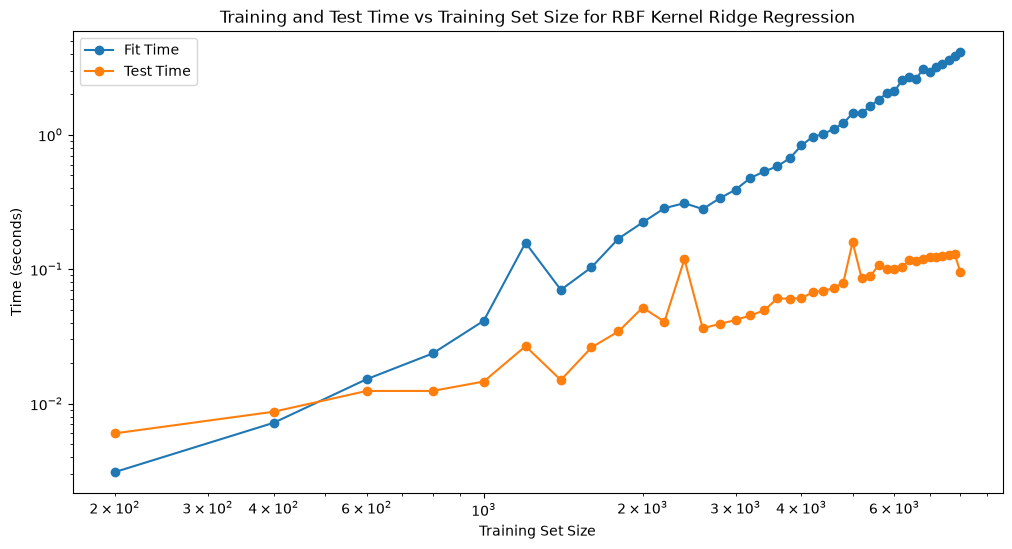

In [28]:
# Plot the timing results
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(timings['training_set_size'], timings['fit_time'], label='Fit Time', marker='o')
plt.plot(timings['training_set_size'], timings['test_time'], label='Test Time', marker='o')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Training Set Size')
plt.ylabel('Time (seconds)')
plt.title('Training and Test Time vs Training Set Size for RBF Kernel Ridge Regression')
plt.legend()
plt.show()


# Exercise 2 (Kernel Support Vector Classification). 

Load the scikit-learn Breast Cancer Wisconsin dataset and split it into training (80%) and test (20%) sets using a stratified
split.
1. Inspect the ranges of the features in the dataset. Fit a support vector classifier SVC(kernel="rbf") with default parameters on the unscaled training data
and evaluate its test accuracy (and inspect the predicted classes). Then wrap
StandardScaler and SVC(kernel="rbf") inside a Pipeline, re-evaluate and compare the results.

2. Using pipelines with StandardScaler, try SVC with kernel="linear", kernel="poly",
and kernel="rbf". Tune the regularisation parameter and kernel parameters via
cross-validation. Compare the test accuracies and the number of support vectors
retained by each winning model.




# Exercise 3 (Kernels and Explainability). 

Load the scikit-learn Breast Cancer Wisconsin dataset and split it into training (80%) and test (20%) sets using a stratified
split.

1. Build pipelines with $\mathtt{StandardScaler}$ for a linear SVM and an SVM with an RBF
kernel. Compare their test accuracies. For the linear model, extract and plot the
top 10 features with the largest absolute weights $|w_j|$. Note that the linear decision
score $\vec w^T \vec x + w_0$ decomposes directly into exact feature contributions $w_j x_j$
for any
standardised input $\vec x$.

2. Using the $\mathtt{lime}$ package, generate local explanations for three test instances: a
confident benign prediction, a confident malignant prediction, and a borderline or
misclassified instance. Do this for both the linear pipeline and the RBF SVM
pipeline (passing the pipeline’s .predict proba method so features remain in their
original units). Compare LIME’s feature weights for the linear model with the exact
contributions wjxj, and check how much LIME explanations vary if you re-run the
explainer with a different random seed.

3. Using the shap package, compute SHAP values for both pipelines (for example, using shap.Explainer on the linear model and shap.KernelExplainer with a summarised background set such as shap.kmeans(X train, 25) for the RBF SVM).
Produce a SHAP summary plot across the test set and waterfall plots for the same
three instances examined before. Compare the global feature importance ranking
of the RBF SVM with the linear model weights above.